In [1]:
using Revise
using Plots
using LaTeXStrings

gr();
# pyplot();
# plotlyjs();

In [2]:
using LinearAlgebra: BLAS; BLAS.set_num_threads(1)

In [3]:
using GaussianSpectralDensities

In [4]:
include("example_problems.jl");

ftype = Float32

σ = ftype(0.5);
τ = ftype(0.8);
λ = ftype(0.0);

N_big = 1024;
ensemble_big = jordan(N_big, λ, σ, τ);

N = 128;
ensemble = jordan(N, λ, σ, τ);

In [5]:
import LazySets

Mevs = unique(eigvals(Array(ensemble_big.M)));

Ar, Jr = sample(ftype, ensemble_big);
Arevs, Jrevs = eigvals(Ar), eigvals(Jr);

Ac, Jc = sample(Complex{ftype}, ensemble_big);
Acevs, Jcevs = eigvals(Ac), eigvals(Jc);

region = spectral_region(Acevs);
xs, ys, zs = autogrid(region);

In [6]:
i, j = 23, 46
za = zs[i, j + 1]
zb = zs[i - 1, j]
zc = zs[i, j];

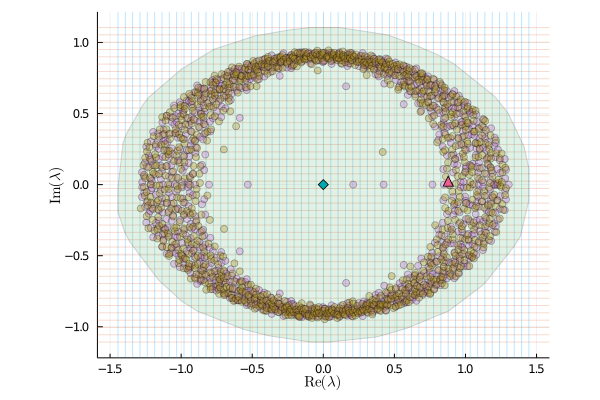

In [7]:
p = vline(xs, label="", alpha=0.25, xlims=(xs[1], xs[end]))
hline!(p, ys, label="", alpha=0.25, ylims=(ys[1], ys[end]))
plot!(
    p,
    region,
    alpha=0.15,
    aspect_ratio=:equal,
    xlabel=L"\mathrm{Re}(\lambda)",
    ylabel=L"\mathrm{Im}(\lambda)",
    tickfontsize=8,
    guidefontsize=10,
)

scatter!(p, real(Arevs), imag(Arevs), alpha=1.0 / 3.0, label="")
scatter!(p, real(Acevs), imag(Acevs), alpha=1.0 / 3.0, label="")
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markersize=5, label="")

scatter!(p, xs[[j]], ys[[i]], markershape=:utriangle, markersize=5, label="")

In [8]:
objective = Fixk();
algorithm = Rampδ²();

In [9]:
verbosity = 3;

solver = SpectralSolver(ensemble, objective, algorithm);
solutiona = solve!(solver, za; verbosity=verbosity, store_trace=true);
solutionb = solve!(solver, zb; verbosity=verbosity, store_trace=true);
qa, δa² = solutiona.q, solutiona.δ²;
qb, δb² = solutionb.q, solutionb.δ²;
qc, δc² = GaussianSpectralDensities.select(qa, qb, δa², δb²);
GaussianSpectralDensities.print_q(qc);
GaussianSpectralDensities.print_δ²(δc²);
solutionc = solve!(
    solver, zc,
    qc, δc²;
    verbosity=verbosity, store_trace=true,
);
solver = nothing;  # Hand workspace over to GC

 z =  0.930 + i 0.024
-------------------------------------------------------------------
    μ       γ²         δ²                  q                k
-------  ----------  ---------  ------------------------  ---------
  1.000   2.560e+02  2.560e+02   6.499e-03 + i-1.698e-04  3.798e-03
  1.000   1.280e+02  1.280e+02   1.188e-02 + i-3.139e-04  7.397e-03
  1.000   6.400e+01  6.400e+01   2.190e-02 + i-5.846e-04  1.409e-02
  1.000   3.200e+01  3.200e+01   3.799e-02 + i-1.030e-03  2.589e-02
  1.000   1.600e+01  1.600e+01   6.035e-02 + i-1.674e-03  4.528e-02
  1.000   8.000e+00  8.000e+00   8.614e-02 + i-2.454e-03  7.477e-02
  1.000   4.000e+00  4.000e+00   1.099e-01 + i-3.212e-03  1.169e-01
  1.000   2.000e+00  2.000e+00   1.266e-01 + i-3.766e-03  1.746e-01
  1.000   1.000e+00  1.000e+00   1.335e-01 + i-4.001e-03  2.519e-01
  1.000   5.000e-01  5.000e-01   1.308e-01 + i-3.909e-03  3.536e-01
  1.000   2.500e-01  2.500e-01   1.205e-01 + i-3.563e-03  4.851e-01
  1.000   1.250e-01  1.250e-01  

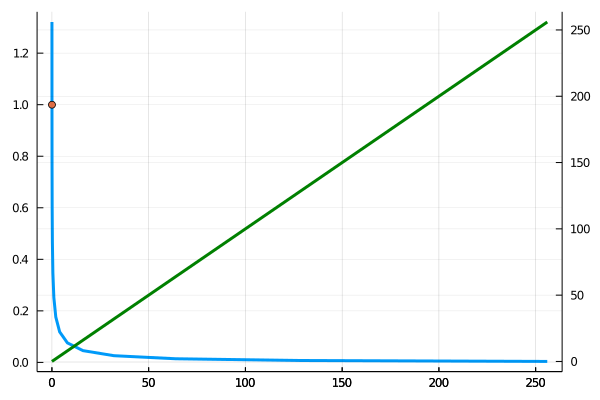

In [10]:
sol = solutionb

plot(sol.trace.γ², sol.trace.k, lw=3, label="")
scatter!([sol.γ²], [sol.k], label="")
plot!(twinx(), sol.trace.γ², sol.trace.δ², lw=3, color=:green, label="")

In [11]:
problem = SpectralProblem(ensemble, objective, zs);
solution = solve(problem, algorithm; chunks_per_thread=1);

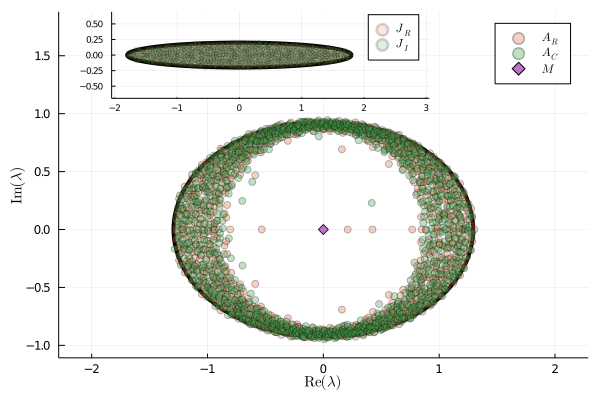

In [12]:
levelfunction = nothing
if objective isa Fixk && objective.value == 1.0
    levelf = solution.γ²
    levels = [0.0]
elseif objective isa Fixγ² && objective.value == 0.0
    levelf = solution.k
    levels = [1.0]
end

p = contour(
    xs,
    ys,
    levelf,
    levels=levels,
    linewidth=4,
    color=:black,
    colorbar_entry=false,
    aspect_ratio=:equal,
    ylims=(ys[1], ys[end] + 0.35 * (ys[end] - ys[1])),
    xlabel=L"\mathrm{Re}(\lambda)",
    ylabel=L"\mathrm{Im}(\lambda)",
    tickfontsize=8,
    guidefontsize=10,
)
scatter!(p, real(Arevs), imag(Arevs), alpha=1.0 / 3.0, label=L"A_R")
scatter!(p, real(Acevs), imag(Acevs), alpha=1.0 / 3.0, label=L"A_C")
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markersize=5, label=L"M")

plot!(
    p,
    t -> (1 + τ) * cos(t),
    t -> (1 - τ) * sin(t),
    0,
    2pi,
    linewidth=4,
    color=:black,
    aspect_ratio=:equal,
    xlims=(-(1 + τ + 0.25), 1 + τ + 1.25),
    tickfontsize=6,
    inset_subplots=(1, bbox(0.1, 0.0, 0.6, 0.25)),
    label="",
    subplot=2,
)
scatter!(
    p,
    real(Jrevs),
    imag(Jrevs),
    markersize=2,
    alpha=1.0 / 6.0,
    aspect_ratio=:equal,
    label=L"J_R",
    subplot=2,
)
scatter!(
    p,
    real(Jcevs),
    imag(Jcevs),
    markersize=2,
    alpha=1.0 / 6.0,
    aspect_ratio=:equal,
    label=L"J_I",
    subplot=2,
)

p

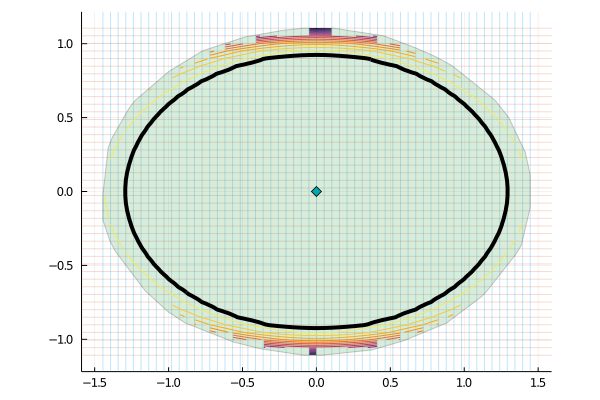

In [13]:
p = vline(xs, xlims=(xs[1], xs[end]), alpha=0.25, label="")
hline!(p, ys, ylims=(ys[1], ys[end]), alpha=0.25, label="")
plot!(p, region, alpha=0.2)
contour!(p, xs, ys, levelf, aspect_ratio=:equal, colorbar=false)
contour!(p, xs, ys, levelf, levels=levels, color=:black, linewidth=4)
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markersize=5, label="")

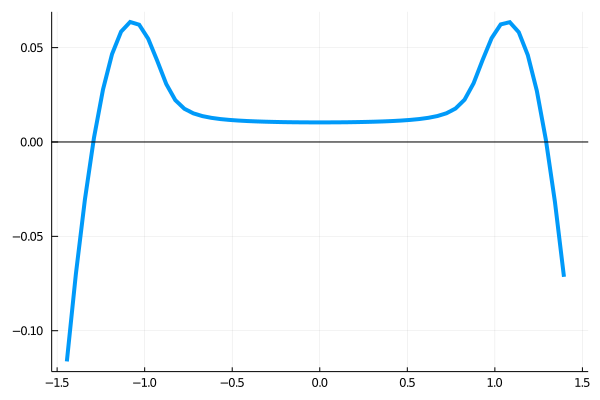

In [14]:
midi = length(ys) ÷ 2
p = plot(xs, levelf[midi, :], linewidth=4, label="")
hline!(p, [0.0], color=:black, label="")

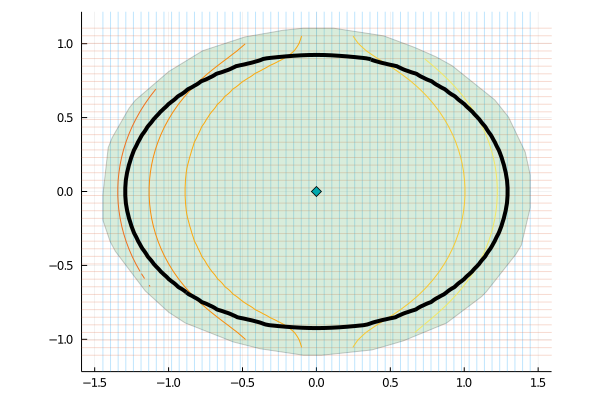

In [15]:
p = vline(xs, xlims=(xs[1], xs[end]), alpha=0.25, label="")
hline!(p, ys, ylims=(ys[1], ys[end]), alpha=0.25, label="")
plot!(p, region, alpha=0.2)
contour!(p, xs, ys, real(solution.q), aspect_ratio=:equal, colorbar=false)
contour!(p, xs, ys, levelf, levels=levels, color=:black, linewidth=4)
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markersize=5, label="")

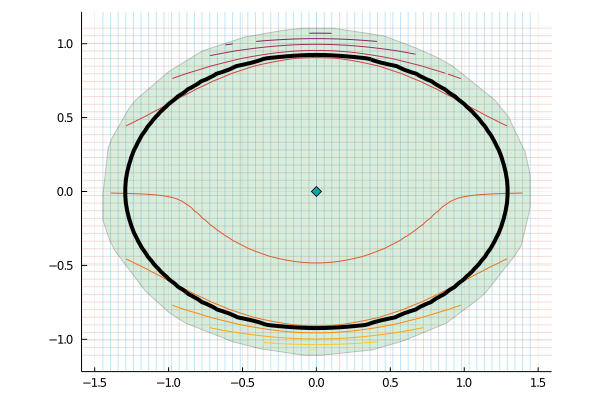

In [16]:
p = vline(xs, xlims=(xs[1], xs[end]), alpha=0.25, label="")
hline!(p, ys, ylims=(ys[1], ys[end]), alpha=0.25, label="")
plot!(p, region, alpha=0.2)
contour!(p, xs, ys, imag(solution.q), aspect_ratio=:equal, colorbar=false)
contour!(p, xs, ys, levelf, levels=levels, color=:black, linewidth=4)
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markersize=5, label="")

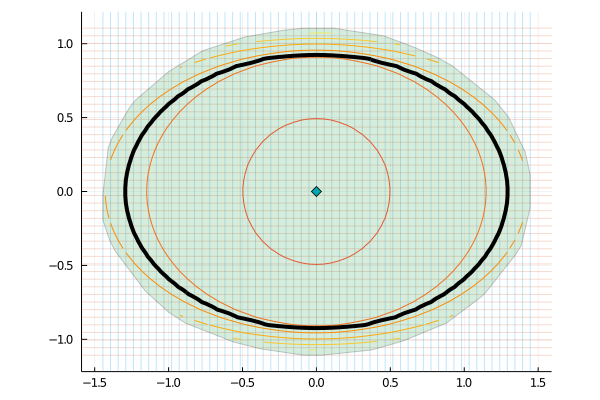

In [17]:
p = vline(xs, xlims=(xs[1], xs[end]), alpha=0.25, label="")
hline!(p, ys, ylims=(ys[1], ys[end]), alpha=0.25, label="")
plot!(p, region, alpha=0.2)
contour!(p, xs, ys, abs.(solution.q), aspect_ratio=:equal, colorbar=false)
contour!(p, xs, ys, levelf, levels=levels, color=:black, linewidth=4)
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markersize=5, label="")

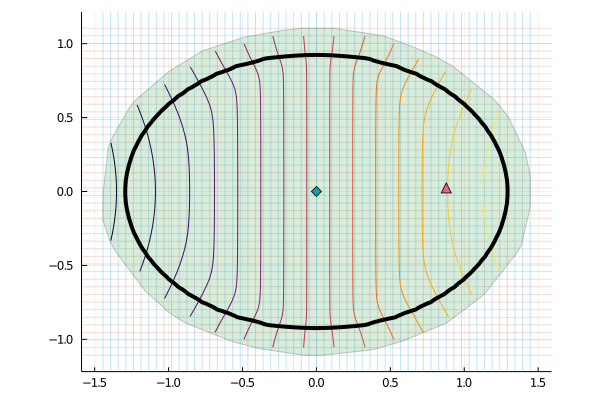

In [18]:
ds = (zs / σ) - sqrt(τ) * solution.q  # Feedforward specific quantity

p = vline(xs, xlims=(xs[1], xs[end]), alpha=0.25, label="")
hline!(p, ys, ylims=(ys[1], ys[end]), alpha=0.25, label="")
plot!(p, region, alpha=0.2)
contour!(p, xs, ys, real(ds), aspect_ratio=:equal, colorbar=false)
contour!(p, xs, ys, levelf, levels=levels, color=:black, linewidth=4)
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markersize=5, label="")

ii, jj = 23, 46
scatter!(p, xs[[jj]], ys[[ii]], markershape=:utriangle, markersize=5, label="")

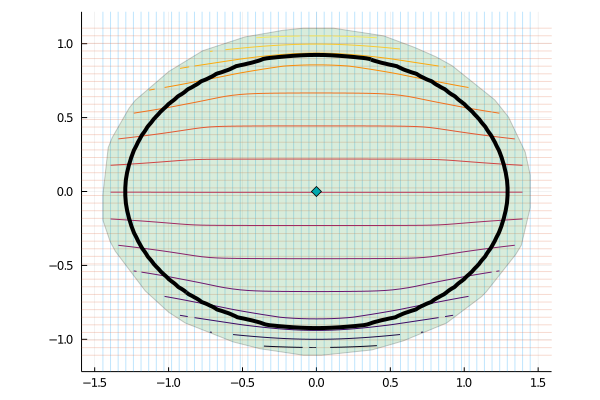

In [19]:
p = vline(xs, xlims=(xs[1], xs[end]), alpha=0.25, label="")
hline!(p, ys, ylims=(ys[1], ys[end]), alpha=0.25, label="")
plot!(p, region, alpha=0.2)
contour!(p, xs, ys, imag(ds), aspect_ratio=:equal, colorbar=false)
contour!(p, xs, ys, levelf, levels=levels, color=:black, linewidth=4)
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markersize=5, label="")

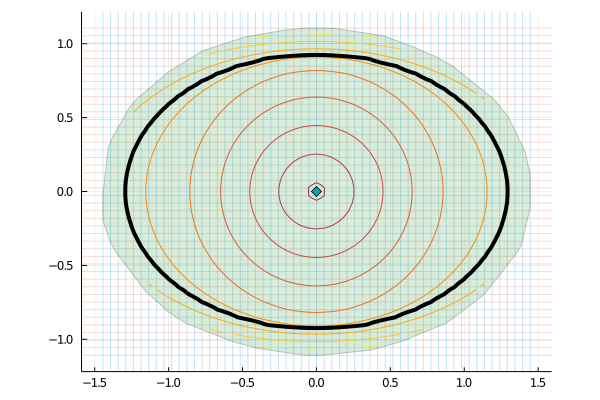

In [20]:
p = vline(xs, xlims=(xs[1], xs[end]), alpha=0.25, label="")
hline!(p, ys, ylims=(ys[1], ys[end]), alpha=0.25, label="")
plot!(p, region, alpha=0.2)
contour!(p, xs, ys, abs.(ds), aspect_ratio=:equal, colorbar=false)
contour!(p, xs, ys, levelf, levels=levels, color=:black, linewidth=4)
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markersize=5, label="")